In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,KFold,cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,Ridge,Lasso,ElasticNet,RidgeCV, LassoCV, ElasticNetCV
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
dt = pd.read_csv("insurance.csv")

In [4]:
dt.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
dt.shape

(1338, 7)

In [12]:
dt.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [11]:
dt.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


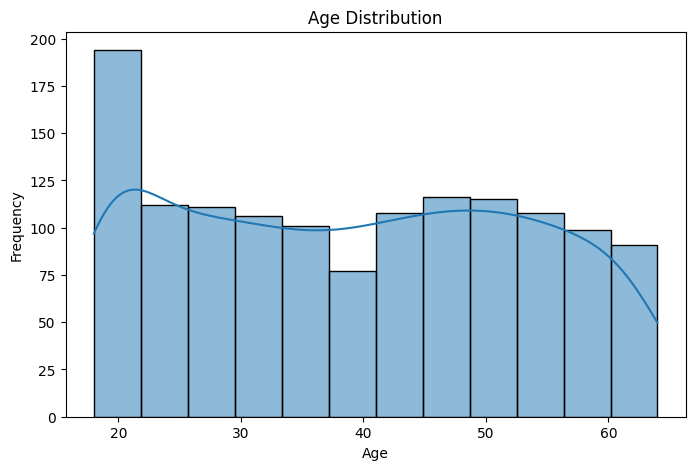

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(data=dt, x='age', kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

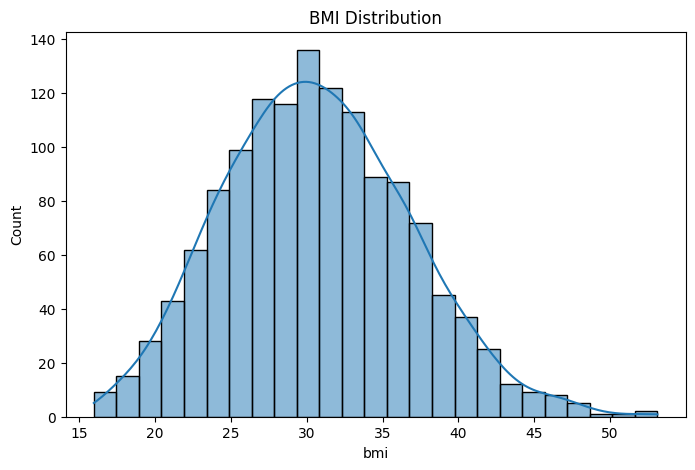

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(data=dt, x='bmi', kde=True)
plt.title('BMI Distribution')
plt.show()

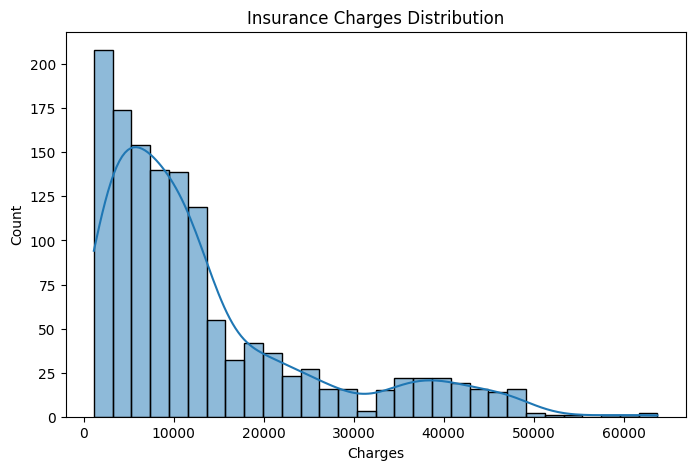

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(data=dt, x='charges', kde=True)
plt.title('Insurance Charges Distribution')
plt.xlabel('Charges')
plt.show()

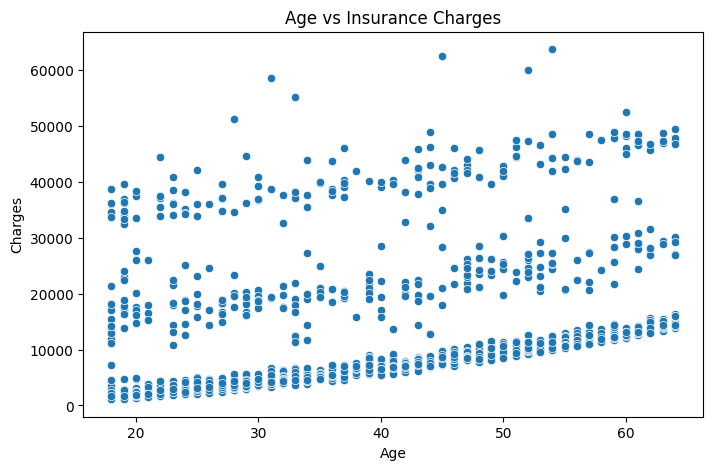

In [20]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=dt, x='age', y='charges')
plt.title('Age vs Insurance Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

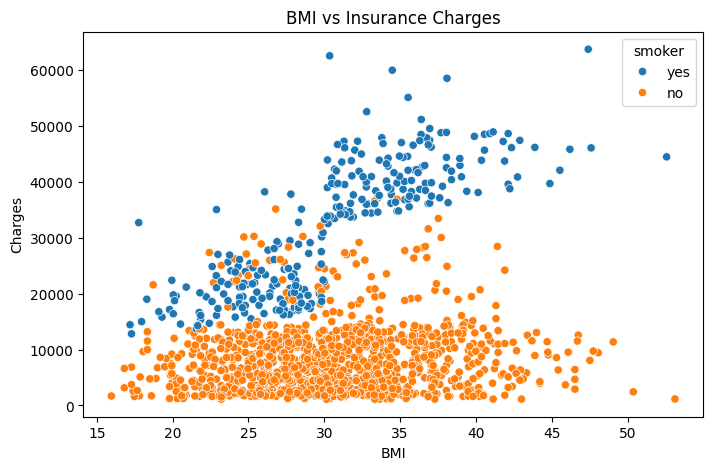

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=dt, x='bmi', y='charges', hue='smoker')
plt.title('BMI vs Insurance Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.show()

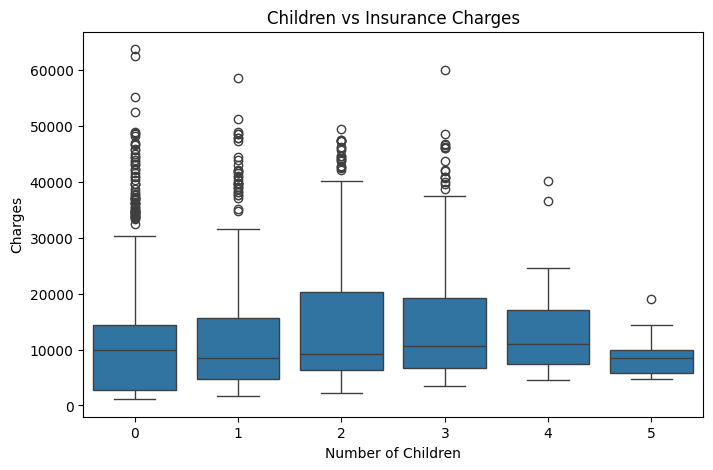

In [22]:
plt.figure(figsize=(8,5))
sns.boxplot(data=dt, x='children', y='charges')
plt.title('Children vs Insurance Charges')
plt.xlabel('Number of Children')
plt.ylabel('Charges')
plt.show()

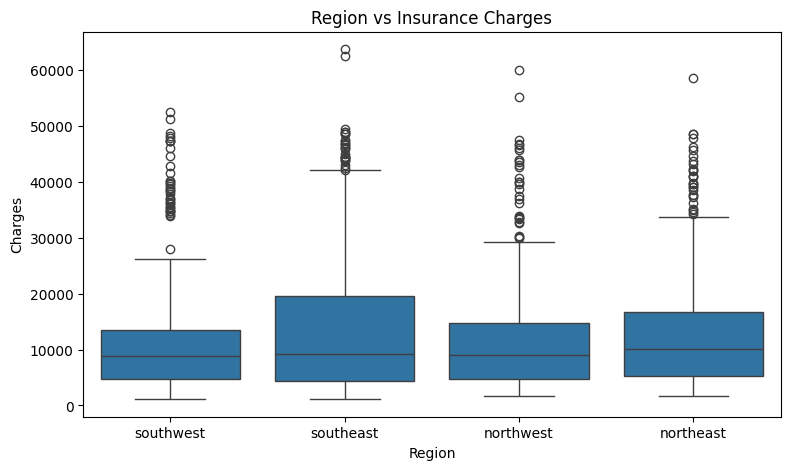

In [23]:
plt.figure(figsize=(9,5))
sns.boxplot(data=dt, x='region', y='charges')
plt.title('Region vs Insurance Charges')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.show()

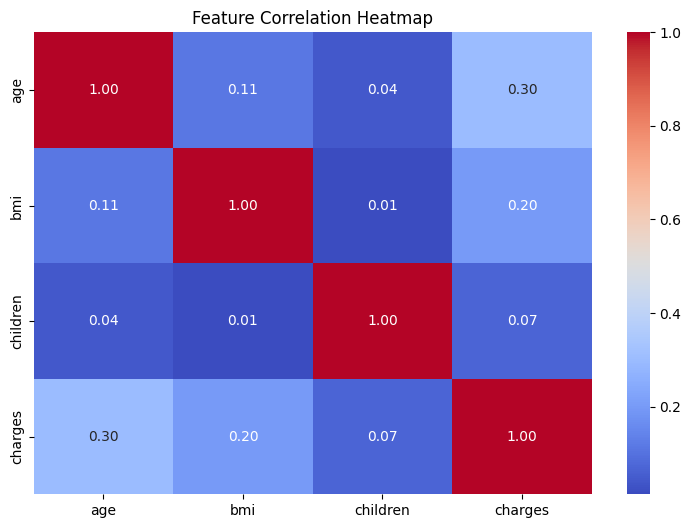

In [24]:
plt.figure(figsize=(9,6))

corr = dt.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()

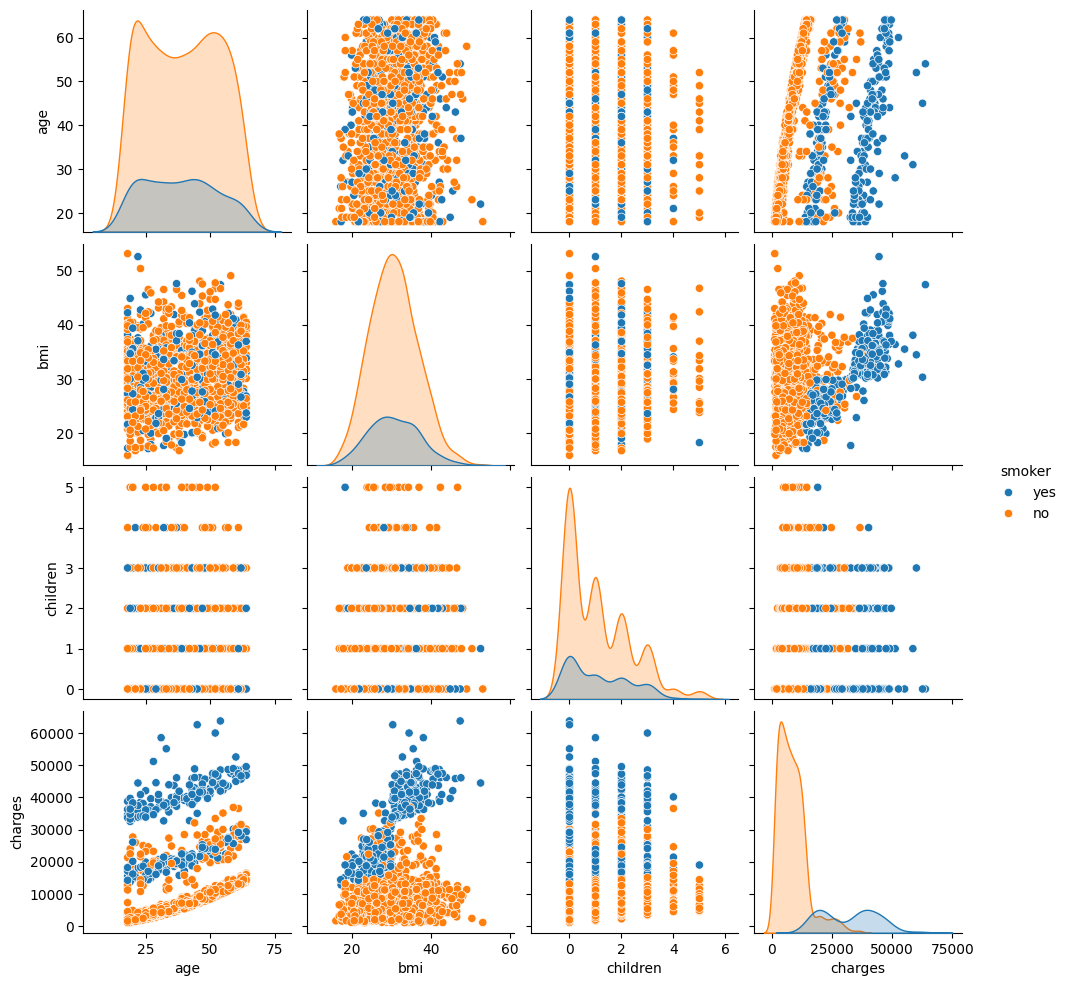

In [25]:
sns.pairplot(
    dt,
    vars=['age', 'bmi', 'children', 'charges'],
    hue='smoker'
)

plt.show()

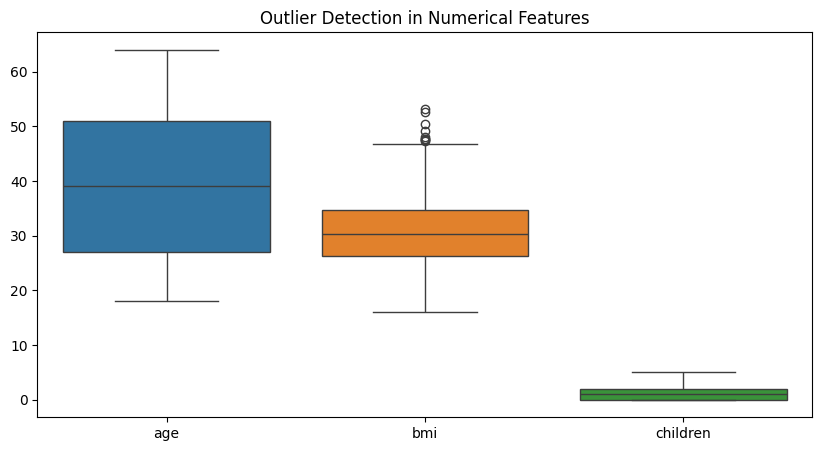

In [27]:
plt.figure(figsize=(10,5))

sns.boxplot(data=dt[['age', 'bmi', 'children']])

plt.title('Outlier Detection in Numerical Features')
plt.show()

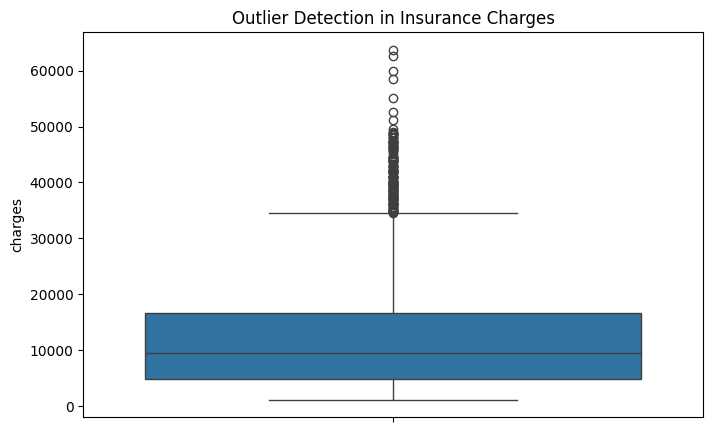

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(y=dt['charges'])

plt.title('Outlier Detection in Insurance Charges')
plt.show()

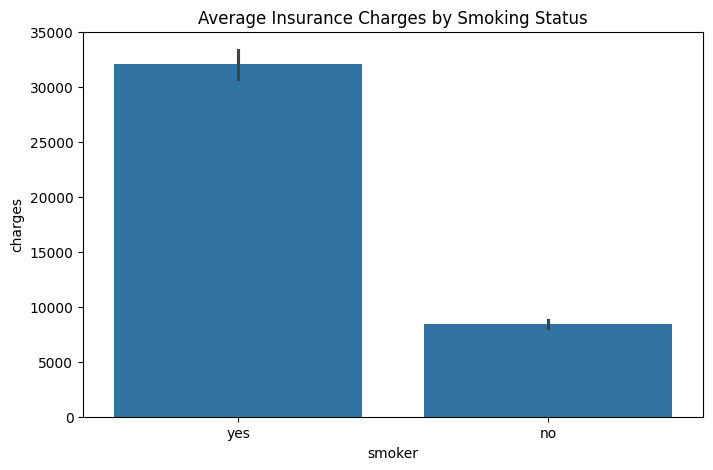

In [29]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=dt,
    x='smoker',
    y='charges',
    estimator='mean'
)

plt.title('Average Insurance Charges by Smoking Status')
plt.show()

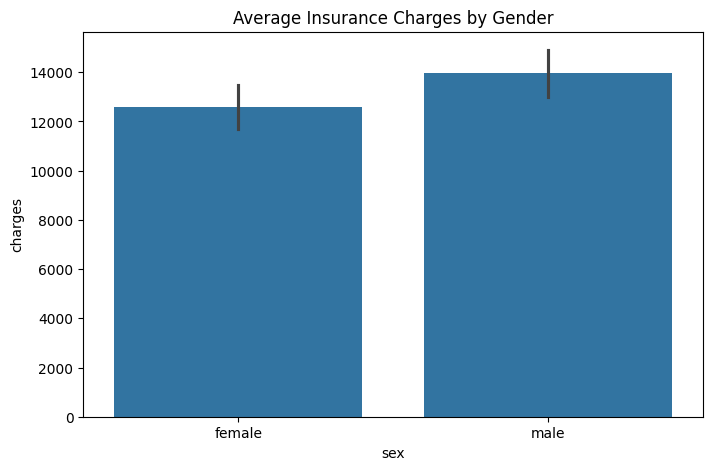

In [30]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=dt,
    x='sex',
    y='charges',
    estimator='mean'
)

plt.title('Average Insurance Charges by Gender')
plt.show()

In [35]:
x = dt[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = dt[['charges']]

In [44]:
x = pd.get_dummies(x, drop_first=True, dtype=int)

x

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...
1333,50,30.970,3,1,0,1,0,0
1334,18,31.920,0,0,0,0,0,0
1335,18,36.850,0,0,0,0,1,0
1336,21,25.800,0,0,0,0,0,1


In [46]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=232)

In [49]:
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Ridge Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0))
    ]),

    'Lasso Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.1, max_iter=10000))
    ]),

    'ElasticNet Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000))
    ])
}

In [54]:
for name, model in models.items():
    model.fit(x_train, y_train)
    print(f'{name} trained successfully')

Linear Regression trained successfully
Ridge Regression trained successfully
Lasso Regression trained successfully
ElasticNet Regression trained successfully


In [55]:
results = []

for name, model in models.items():

    y_pred = model.predict(x_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df)

                   Model          MAE           MSE         RMSE  R2 Score
0      Linear Regression  4280.747737  3.615027e+07  6012.509664  0.738011
1       Ridge Regression  4281.609293  3.614545e+07  6012.108967  0.738046
2       Lasso Regression  4280.709233  3.614999e+07  6012.486399  0.738013
3  ElasticNet Regression  4333.957944  3.614171e+07  6011.797689  0.738073


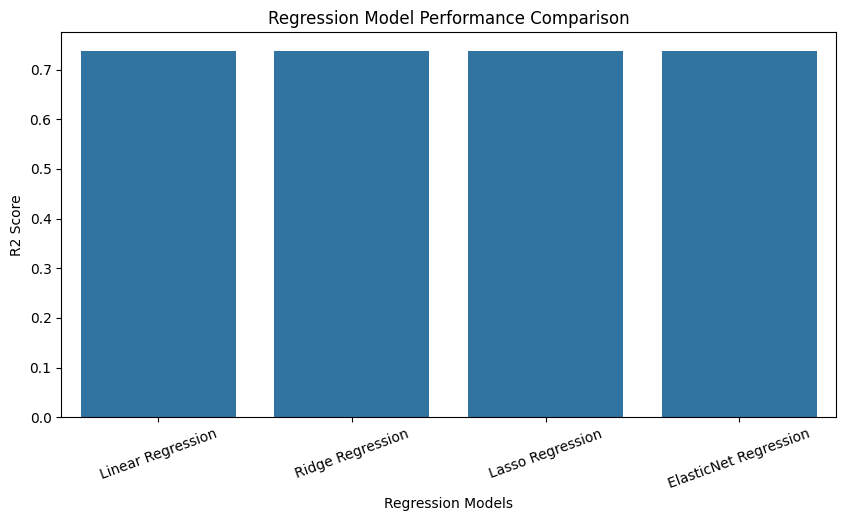

In [56]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Regression Model Performance Comparison')
plt.xlabel('Regression Models')
plt.ylabel('R2 Score')
plt.xticks(rotation=20)
plt.show()

In [57]:
#checking overfiting and underfiting

results = []

for name, model in models.items():

    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    results.append({
        'Model': name,
        'Train R2': train_r2,
        'Test R2': test_r2,
        'R2 Gap': train_r2 - test_r2,
        'Train MAE': train_mae,
        'Test MAE': test_mae,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                   Model  Train R2  Test R2  R2 Gap  Train MAE   Test MAE  \
0      Linear Regression    0.7535   0.7380  0.0155  4161.6773  4280.7477   
1       Ridge Regression    0.7535   0.7380  0.0155  4162.5897  4281.6093   
2       Lasso Regression    0.7535   0.7380  0.0155  4161.6621  4280.7092   
3  ElasticNet Regression    0.7518   0.7381  0.0138  4225.5994  4333.9579   

   Train RMSE  Test RMSE  
0   6052.0745  6012.5097  
1   6052.0825  6012.1090  
2   6052.0745  6012.4864  
3   6072.6423  6011.7977  


In [60]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error'
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True
    )

    results.append({
        'Model': name,
        'Train R2': scores['train_R2'].mean(),
        'CV R2': scores['test_R2'].mean(),
        'R2 Std': scores['test_R2'].std(),
        'Train MAE': -scores['train_MAE'].mean(),
        'CV MAE': -scores['test_MAE'].mean(),
        'Train RMSE': -scores['train_RMSE'].mean(),
        'CV RMSE': -scores['test_RMSE'].mean()
    })

cv_results = pd.DataFrame(results)

print(cv_results.round(4))

                   Model  Train R2   CV R2  R2 Std  Train MAE     CV MAE  \
0      Linear Regression    0.7540  0.7423  0.0470  4159.1845  4210.1924   
1       Ridge Regression    0.7540  0.7424  0.0469  4160.3671  4211.3605   
2       Lasso Regression    0.7540  0.7423  0.0470  4159.1743  4210.1840   
3  ElasticNet Regression    0.7523  0.7416  0.0438  4221.9615  4268.8351   

   Train RMSE    CV RMSE  
0   6042.2498  6106.5492  
1   6042.2623  6106.4249  
2   6042.2498  6106.5512  
3   6062.9282  6122.0448  
